# 4 · Strategies, one fair comparison

`03_upscale_web.ipynb` made one architecture fast, and `07_upscale_luma.ipynb` found a
better one. This notebook asks which of its ideas are worth keeping: each is trained with
the same data, the same recipe and the same seed, and the control is trained again at
other seeds to see how far apart luck alone puts two runs - a smaller gap than that says
nothing.

Every strategy keeps notebook 3's frame (frozen bicubic skip, residual at low resolution,
one `PixelShuffle`), fits the client's 4-pixel halo, and uses only operators in the
browser's fast set. Two ideas are tested against notebook 3's model:

- **Luma only** - the network corrects brightness and leaves colour to bicubic: less to
  run, and colour cannot drift.
- **Residual blocks** - a deeper body inside the same halo, paid in memory traffic.

Three more ideas were tried and landed within luck of the control - reparameterization, a
leaky ReLU and a separate colour branch (`summary.md`, "Strategies") - so they are not
trained again.

Steps:

1. **Data** - load the patch pairs.
2. **Models** - every strategy, its size and its halo; each must start as bicubic.
3. **Speed** - is each fast enough for a live stream? Checked before training.
4. **Train** - every strategy until it has converged, then the control at two more seeds:
   the gap luck alone makes.
5. **Save** - the winner, and a whole frame through it.
6. **Export** - the best two at the client's tile.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "Strategies".
Writes `checkpoints/upscale_strategies.pt`, which `09_upscale_dct.ipynb` and
`10_upscale_lut.ipynb` compare with, and each run's training to `checkpoints/strategy_runs/`.

In [2]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from helpers import metrics, models, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_strategies.pt"   # the winner
RUN_DIR = training.CHECKPOINT_DIR / "strategy_runs"               # each run's training, saved every epoch
FRAME_DIR = DATA_DIR / "synthetic"

MAX_EPOCHS = 500        # a safety limit; each training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0
CONTROL_SEEDS = (1, 2)  # the control trained again: how far apart luck alone puts two runs
PUBLISH = 2             # how many of the best strategies to export

STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
ESTIMATE_ON = {                          # devices for the runtime estimate (speed.HARDWARE)
    "Iris Xe": "Intel Iris Xe, 96 EU (laptop iGPU)",
    "GTX 1650": "NVIDIA GTX 1650",
    "RTX 3060": "NVIDIA RTX 3060",
}

training.seed_everything(SEED)

## 1. Data

`train` is what the models learn from, with random flips and rotations as free extra
examples. `val` is held out: every score below is measured on it.

The LR patches carry a halo of extra pixels, so a model's output is a bit too large;
`trim` cuts that border off before the loss and the scores.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  17140 patches from 1089 sources
val     3523 patches from 225 sources
lr batch (32, 3, 72, 72)  hr batch (32, 3, 128, 128)


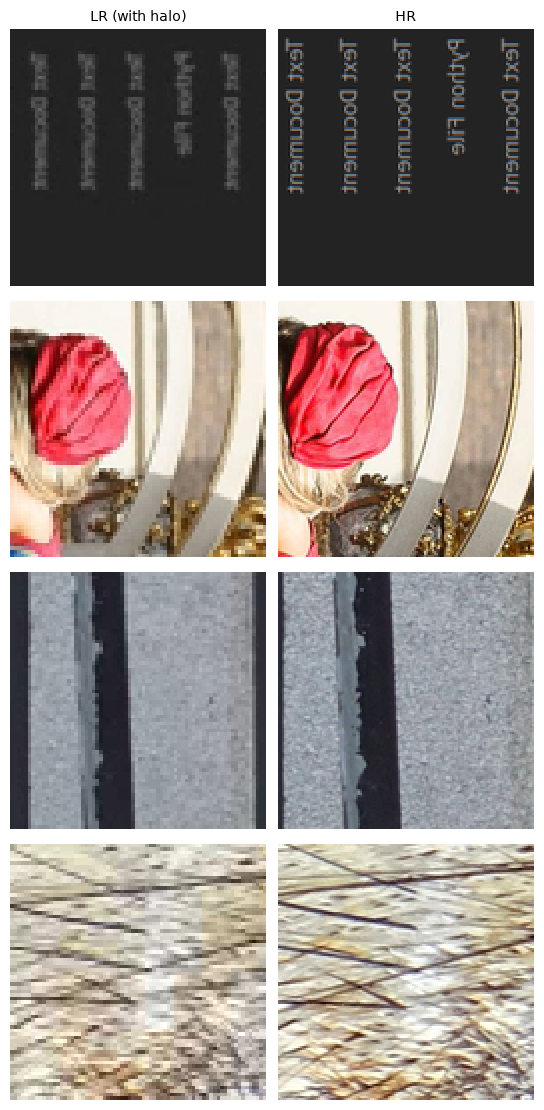

In [3]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128)
trim = training.trimmer(manifest)

lr_batch, hr_batch = next(iter(train_loader))
print("lr batch", tuple(lr_batch.shape), " hr batch", tuple(hr_batch.shape))
training.show_patches({"LR (with halo)": lr_batch[:4], "HR": hr_batch[:4]})

## 2. Models

Every strategy is a model from `helpers/models.py`: notebook 3's frame, with a body of its
own. The output convolution starts at zero, so every untrained model is exactly bicubic.

    LR --> bicubic skip (fixed 5x5 conv) ------------------+
    LR --> body -> output conv (starts at zero) -----------+--> add --> PixelShuffle --> HR

| strategy | model | body | what it tests |
|---|---|---|---|
| `32-16` | `PlainUpscaler` | notebook 3's model: 5x5 to 32, 3x3 to 16, RGB correction | the control |
| `luma 32-16` | `LumaUpscaler` | the control's body, correcting brightness only | colour left to bicubic |
| `luma 24 + 2 blocks` | `LumaUpscaler` | notebook 7's model: 3x3 to 24, two residual blocks | residual blocks |

**Halo.** Every body reaches 4 pixels, within the halo of the patches and of the client's
tiles.

In [4]:
"""Every strategy: name -> (model class, its arguments)."""

STRATEGIES = {
    "32-16": (models.PlainUpscaler, dict(widths=(32, 16), stem=5)),
    "luma 32-16": (models.LumaUpscaler, dict(widths=(32, 16), blocks=0, stem=5)),
    "luma 24 + 2 blocks": (models.LumaUpscaler, dict(widths=(24,), blocks=2, stem=3)),
}
CONTROL = "32-16"


def build(name, seed=SEED):
    """A fresh, untrained model of one strategy."""
    model_class, arguments = STRATEGIES[name]
    torch.manual_seed(seed)
    return model_class(scale=SCALE, **arguments).to(DEVICE)


def slug(name):
    """A strategy's name as a file name: "luma 24 + 2 blocks" -> "luma_24_2_blocks"."""
    return "_".join(name.replace("+", " ").split())

In [5]:
"""Before training: each model's size, and it must start exactly as bicubic."""

lr_probe = next(iter(val_loader))[0][:8].to(DEVICE)
built = {}
print(f"{'strategy':<22}{'learned params':>16}{'MACs / LR px':>14}{'halo':>6}{'vs bicubic':>12}")
for name in STRATEGIES:
    model = built[name] = build(name)
    assert model.halo <= manifest["halo"], f"{name}: reaches further than the patches' halo"
    with torch.no_grad(), training.full_precision():
        start = (trim(model(lr_probe)) - trim(models.bicubic(lr_probe, SCALE))).abs().max().item()
    assert start < 1e-5, f"{name}: the untrained model is not bicubic ({start:.1e})"
    print(f"{name:<22}{models.count_parameters(model, True):>16,}{speed.macs_per_lr_pixel(model):>14,.0f}"
          f"{model.halo:>6}{start:>12.1e}")

strategy                learned params  MACs / LR px  halo  vs bicubic
32-16                            8,796         9,636     4     4.2e-07
luma 32-16                       7,636         8,484     4     4.2e-07
luma 24 + 2 blocks              13,156        13,932     4     4.2e-07


## 3. Speed - is each fast enough?

A model that misses the frame time is no use for a live stream, however good it looks.
Speed depends on the shape, not the weights, so it is checked before training. Each graph
must also use only operators in the browser's fast set.

As in notebook 3, `webexport.count_work` counts the operations (a multiply-add is 2) and
the memory traffic in the ONNX graph of one client tile, and a 1080p frame costs that
times its tiles. The **roofline** estimate gives a device the slower of *operations / peak
compute* and *bytes / bandwidth*. This computer's GPU runs the control to see what share
of its peak it reaches, and every strategy on every device is assumed to reach the same
share, so the estimates rank the strategies by their work. `measured` is one whole 1080p
frame through torch on this computer. Read the estimates as a best case: 16.7 ms is a
60 fps frame, 33.3 ms a 30 fps one.

In [6]:
"""The work in one client tile of each strategy, and the time for a 1080p frame."""

plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=manifest["halo"])
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
frame_lr = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)


def frame_work(cost, pixels, runs):
    """Operations and bytes for `pixels` LR pixels, computed in `runs` runs of the graph."""
    return {"operations": pixels * cost["ops"], "bytes": pixels * cost["bytes"] + runs * cost["weight_bytes"]}


costs = {}
for name, model in built.items():
    # into checkpoints/, not dist/, so the benchmark page does not list it
    graph = webexport.export(model, f"speed_check_{slug(name)}.onnx", tile_shape, halo=model.halo,
                             models_dir=training.CHECKPOINT_DIR / "speed")
    assert not graph["outside_budget"], f"{name} uses {graph['outside_budget']}, outside the fast operators"
    work = webexport.count_work(graph["path"])
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model.eval()(frame_lr), seconds=1.0)
    costs[name] = {"ops": work["operations"] / work["input_pixels"],          # per LR pixel
                   "bytes": work["activation_bytes"] / work["input_pixels"],  # per LR pixel
                   "weight_bytes": work["weight_bytes"], "measured_ms": measured_ms}

# calibrate: the share of its peak this GPU reaches on the control, run as one whole frame
if DEVICE.type == "cuda":
    whole_frame = frame_work(costs[CONTROL], frame_lr.shape[2] * frame_lr.shape[3], runs=1)
    best_ms, _ = speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])
    efficiency = best_ms / costs[CONTROL]["measured_ms"]
    print(f"{speed.THIS_GPU} reaches {efficiency:.0%} of its peak on the control; every estimate assumes the same")
else:
    efficiency = 1.0
    print("no GPU here to calibrate on: the estimates below are the roofline itself, a best case")

tiled_pixels = plan["runs"] * tile_shape[0] * tile_shape[1]   # LR pixels of a frame's tiles, halos included
print(f"\nms per 1080p frame, {plan['runs']} tiles of {tile_shape[1]}x{tile_shape[0]} "
      f"(c = compute-bound, m = memory-bound)")
print(f"{'strategy':<22}{'ops / LR px':>12}{'bytes / LR px':>15}{'measured':>10}"
      + "".join(f"{short:>12}" for short in ESTIMATE_ON))
for name, cost in costs.items():
    row = f"{name:<22}{cost['ops']:12,.0f}{cost['bytes']:15,.0f}{cost['measured_ms']:10.2f}"
    for short, device in ESTIMATE_ON.items():
        ms, limit = speed.roofline_ms(frame_work(cost, tiled_pixels, plan["runs"]), *speed.HARDWARE[device])
        cost[short] = ms / efficiency
        row += f"{cost[short]:>9.1f} ({limit[0]})"
    print(row)

NVIDIA RTX 3090 reaches 38% of its peak on the control; every estimate assumes the same

ms per 1080p frame, 9 tiles of 328x188 (c = compute-bound, m = memory-bound)
strategy               ops / LR px  bytes / LR px  measured     Iris Xe    GTX 1650    RTX 3060
32-16                       19,392          1,128      1.64     24.2 (m)     12.9 (m)      4.6 (m)
luma 32-16                  17,080          1,192      1.63     25.6 (m)     13.6 (m)      4.8 (m)
luma 24 + 2 blocks          28,120          2,536      3.22     54.4 (m)     28.9 (m)     10.3 (m)


## 4. Train

The recipe of notebooks 2, 3 and 7, for every strategy: the loss is `metrics.ssim_l1_loss`
(0.84 x (1 - SSIM on luma) + 0.16 x L1 on RGB), and after every epoch the epoch with the
best luma SSIM (`ssim-y`) is kept. Each strategy trains until the score stops improving,
halving the learning rate at every plateau, so each gets as many epochs as it needs. Every
training starts from the same seed, which also gives every strategy the same batches in
the same order.

Each run is saved to `checkpoints/strategy_runs/` after every epoch: run the cell again
after an interruption and it carries on, and finished runs just load. Delete a run's file
to train it again. All five runs take about 45 minutes on an RTX 3090.

In [7]:
def train(name, seed=SEED):
    """Train a fresh model of one strategy, or load its saved training. Returns the model at
    its best epoch, the per-epoch history and the best epoch."""
    model = build(name, seed)
    torch.manual_seed(seed)   # the same batches in the same order, whatever the model's size
    run_file = RUN_DIR / f"{slug(name)}_seed{seed}_lr{LEARNING_RATE:g}.pt"
    history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS,
                                   learning_rate=LEARNING_RATE, loss_fn=metrics.ssim_l1_loss,
                                   select="ssim", checkpoint=run_file, verbose=0)
    print(f"{name:<22} seed {seed}: best epoch {best['epoch']:3} of {len(history):3}, ssim-y {best['score']:.4f}")
    return model, history, best


baseline = training.evaluate(models.Resize(SCALE).to(DEVICE), val_loader, trim)
trained, histories, bests, results = {}, {}, {}, {"bicubic": baseline}
for name in STRATEGIES:
    trained[name], histories[name], bests[name] = train(name)
    results[name] = training.evaluate(trained[name], val_loader, trim)

32-16                  seed 0: best epoch  98 of 116, ssim-y 0.9261
luma 32-16             seed 0: best epoch 141 of 147, ssim-y 0.9264
luma 24 + 2 blocks     seed 0: best epoch  98 of 116, ssim-y 0.9286


### How big must a difference be?

One training is partly luck: another seed starts from other weights and sees the batches
in another order. So the control is trained at two more seeds, and every strategy is then
compared with the *mean* of the control's three runs - not with one of them, which may be
its luckiest or its unluckiest. A gap no wider than the spread of those runs is luck.

In [8]:
seed_runs = {f"seed {SEED}": results[CONTROL]}
for seed in CONTROL_SEEDS:
    model, _, _ = train(CONTROL, seed)
    seed_runs[f"seed {seed}"] = training.evaluate(model, val_loader, trim)
seeds = list(seed_runs.values())
spread = {key: max(s[key] for s in seeds) - min(s[key] for s in seeds) for key in ("ssim", "wpsnr")}
control_mean = {key: float(np.mean([s[key] for s in seeds])) for key in ("ssim", "wpsnr")}

print()
metrics.print_table(seed_runs)
print(f"\nthe control at {len(seeds)} seeds: {spread['ssim']:.4f} ssim-y and {spread['wpsnr']:.2f} dB wpsnr apart, "
      f"a mean of {control_mean['ssim']:.4f} ssim-y and {control_mean['wpsnr']:.2f} dB wpsnr")

32-16                  seed 1: best epoch 135 of 141, ssim-y 0.9263
32-16                  seed 2: best epoch  97 of 109, ssim-y 0.9265

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
seed 0              34.97    34.10    43.10    44.08     32.72   0.9243
seed 1              34.96    34.09    43.08    44.07     32.72   0.9248
seed 2              35.08    34.21    43.23    44.17     32.80   0.9252

the control at 3 seeds: 0.0008 ssim-y and 0.11 dB wpsnr apart, a mean of 0.9248 ssim-y and 35.00 dB wpsnr


### The result

Every strategy against the mean of the control's seeds, best first. **better** or
**worse** means the gap is wider than the seeds' spread; **luck** means this validation set
cannot tell the two apart.

The first table judges `ssim-y`, which ranks the strategies. The second judges `wpsnr` -
the brightness error weighted 6 times either colour error, so it is where keeping colour
at bicubic shows - and puts each strategy next to its cost.

In [9]:
def verdict(name, key):
    """A strategy's gap to the mean of the control's seeds, and whether it is more than luck."""
    gap = results[name][key] - control_mean[key]
    if name == CONTROL:
        return gap, "control"
    if abs(gap) <= spread[key]:
        return gap, "luck"
    return gap, "better" if gap > 0 else "worse"


def ssim_verdict(name, scores):
    """The last column of the first table."""
    if name == "bicubic":
        return ""
    gap, word = verdict(name, "ssim")
    return f"{gap:+11.4f}  {word}"


order = sorted(STRATEGIES, key=lambda name: -results[name]["ssim"])   # best first
best_name = order[0]

print(f"last column: ssim-y against the control's mean of {control_mean['ssim']:.4f}")
metrics.print_table({name: results[name] for name in ["bicubic", *order]}, extra=ssim_verdict)

print(f"\n{'strategy':<22}{'ssim-y vs bicubic':>18}{'wpsnr vs control':>22}{'epochs':>8}{'ops / LR px':>13}"
      + "".join(f"{short:>10}" for short in ESTIMATE_ON) + "   ms per 1080p frame (estimate)")
for name in order:
    gap, word = verdict(name, "wpsnr")
    print(f"{name:<22}{results[name]['ssim'] - baseline['ssim']:+18.4f}{gap:+14.2f}  {word:<6}"
          f"{len(histories[name]):8}{costs[name]['ops']:13,.0f}"
          + "".join(f"{costs[name][short]:10.1f}" for short in ESTIMATE_ON))
print(f"\nbest: {best_name}")

last column: ssim-y against the control's mean of 0.9248
                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                 34.14    33.18    50.67    51.46     32.02   0.9049
luma 24 + 2 blocks      35.33    34.45    50.70    51.49     32.96   0.9292    +0.0044  better
luma 32-16              35.09    34.20    50.70    51.49     32.78   0.9249    +0.0002  luck
32-16                   34.97    34.10    43.10    44.08     32.72   0.9243    -0.0004  control

strategy               ssim-y vs bicubic      wpsnr vs control  epochs  ops / LR px   Iris Xe  GTX 1650  RTX 3060   ms per 1080p frame (estimate)
luma 24 + 2 blocks               +0.0243         +0.33  better     116       28,120      54.4      28.9      10.3
luma 32-16                       +0.0200         +0.09  luck       147       17,080      25.6      13.6       4.8
32-16                            +0.0194         -0.04  control     116       19,392      24.2      12.9       4.6

best: luma 24 + 

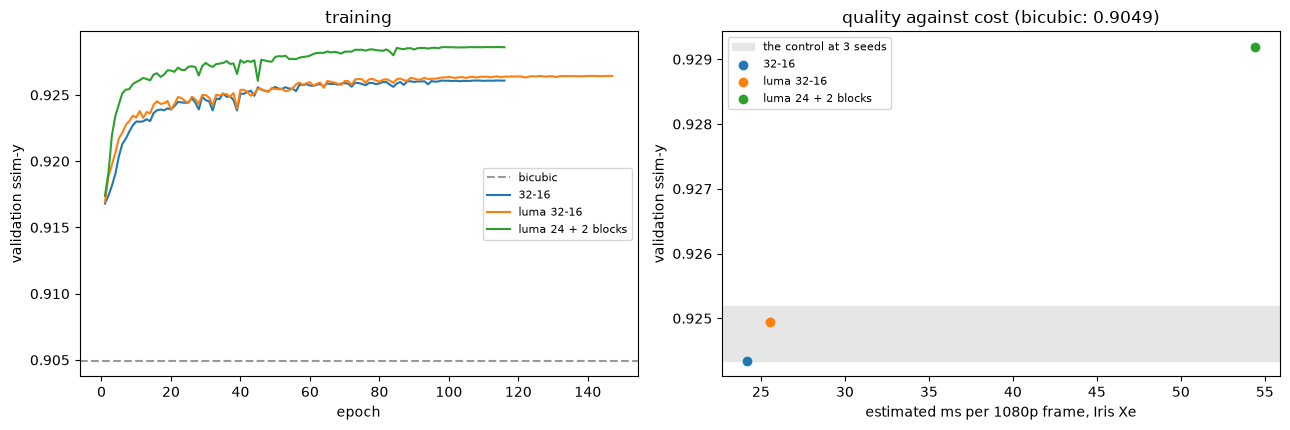

In [10]:
"""Training curves, and quality against cost."""

device = next(iter(ESTIMATE_ON))
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.4))
left.axhline(baseline["ssim"], color="0.6", linestyle="--", label="bicubic")
right.axhspan(min(s["ssim"] for s in seeds), max(s["ssim"] for s in seeds), color="0.9",
              label=f"the control at {len(seeds)} seeds")
for index, name in enumerate(STRATEGIES):
    epochs = range(1, len(histories[name]) + 1)
    left.plot(epochs, [h["ssim"] for h in histories[name]], color=f"C{index}", label=name)
    right.scatter(costs[name][device], results[name]["ssim"], color=f"C{index}", label=name)
left.set(title="training", xlabel="epoch", ylabel="validation ssim-y")
right.set(title=f"quality against cost (bicubic: {baseline['ssim']:.4f})",
          xlabel=f"estimated ms per 1080p frame, {device}", ylabel="validation ssim-y")
left.legend(fontsize=8)
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

### What it looks like

Bicubic, the control and the best strategy. Check text lines and window edges - that is
what a desktop stream is made of.

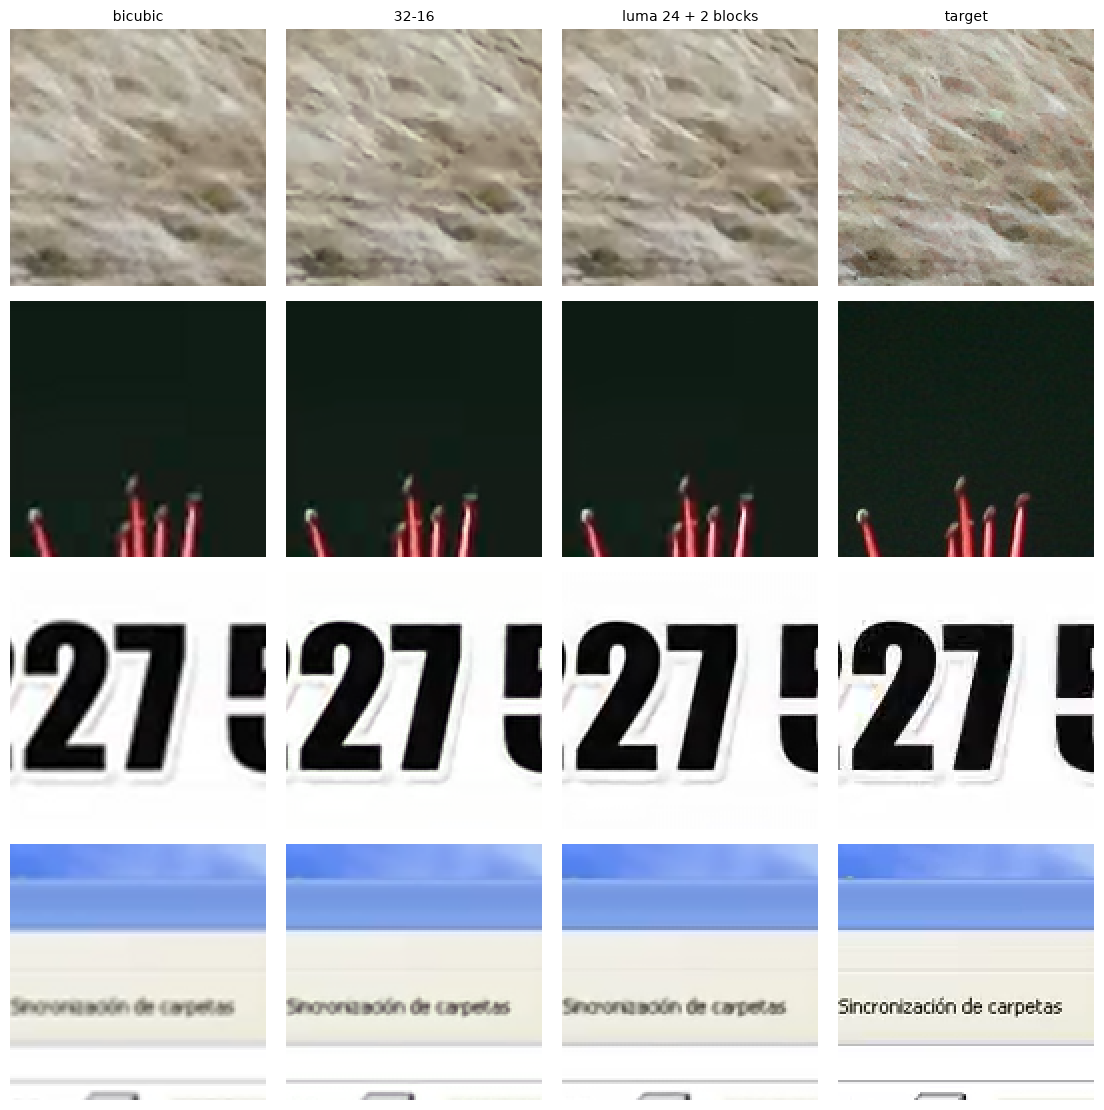

In [11]:
picks = [0, 400, 900, 1600]   # far apart in the set, so from different sources
lr = torch.stack([val_loader.dataset[i][0] for i in picks]).to(DEVICE)
hr = torch.stack([val_loader.dataset[i][1] for i in picks]).to(DEVICE)
with torch.no_grad():
    training.show_patches({
        "bicubic": trim(models.bicubic(lr, SCALE)),
        CONTROL: trim(trained[CONTROL].eval()(lr)),
        best_name: trim(trained[best_name].eval()(lr)),
        "target": hr,
    })

## 5. Save and reload

The checkpoint holds the winner's weights *and* everything needed to rebuild it. We load
it into a fresh model and check it computes the same thing.

In [12]:
winner = trained[best_name]
training.save_checkpoint(CHECKPOINT, winner, architecture=type(winner).__name__,
                         arguments=STRATEGIES[best_name][1], strategy=best_name, scale=SCALE,
                         halo=winner.halo, loss="ssim_l1_loss", select="ssim", learning_rate=LEARNING_RATE,
                         epochs=len(histories[best_name]), best_epoch=bests[best_name]["epoch"],
                         val=results[best_name], val_bicubic=baseline, control_mean=control_mean,
                         seed_spread=spread, degradation=manifest["degradation"])

# rebuild the model from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
model_class = getattr(models, checkpoint["architecture"])
loaded = model_class(scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(winner, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_strategies.pt (62 KB)
reloaded model is identical


### A whole frame

The drawn desktop frame of notebooks 3 and 7, downscaled with bicubic and no codec, so the
numbers compare with theirs.

                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                 25.82    25.09    29.55    29.01     23.92   0.9437
32-16                   27.10    26.56    29.55    29.02     24.84   0.9609
luma 24 + 2 blocks      27.68    27.26    29.57    29.02     25.23   0.9656


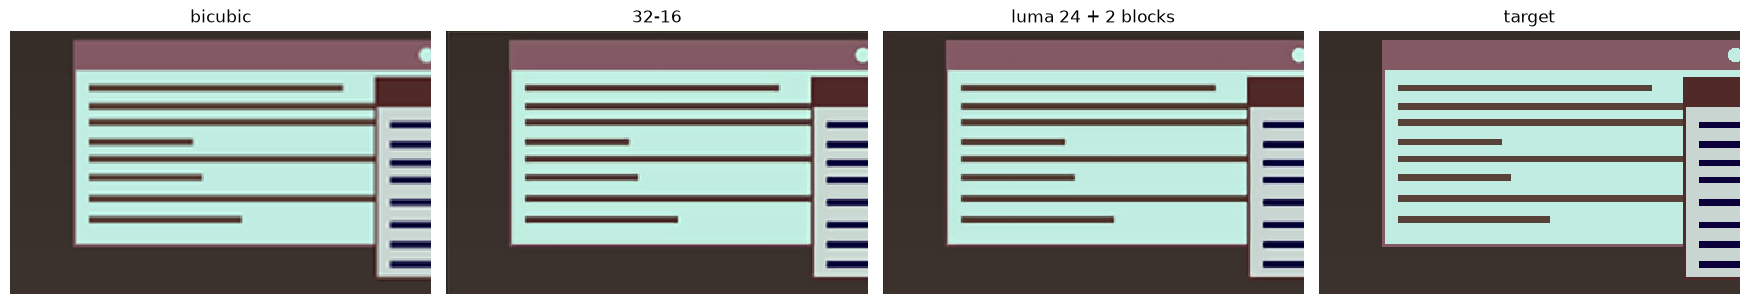

In [13]:
truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = training.to_tensor(truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC))
target = training.to_tensor(truth)

with torch.no_grad():
    upscaled = {"bicubic": models.bicubic(small, SCALE), CONTROL: trained[CONTROL].eval()(small),
                best_name: loaded.eval()(small)}
metrics.print_table({name: metrics.report(image, target) for name, image in upscaled.items()})
Image.fromarray(training.to_image(upscaled[best_name])).save(training.SAMPLE_DIR / "upscaled_strategies.png")

box = (slice(0, 200), slice(0, 320))
panels = {**upscaled, "target": target}
fig, axes = plt.subplots(1, len(panels), figsize=(4.4 * len(panels), 3.4))
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(training.to_image(image)[box], interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Export for the browser

The best `PUBLISH` strategies at the tile a client runs (a 320x180 step,
`05_upscale_geometry.ipynb`), like notebook 7: float32, float16 (half the size), and
float16 as one whole 1080p frame. Each graph is checked against the torch model first.

In [14]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, model, shape, dtype, tolerance):
    """Check a written graph against the torch model, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], model, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
for name in order[:PUBLISH]:
    model = trained[name].eval()
    tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, model.halo)
    frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, model.halo)
    file, label = f"upscale_strategy_{slug(name)}", f"strategy {name}"

    fp32 = webexport.export(model, f"{file}_{tile_name}.onnx", tile_shape, label=f"{label} fp32", halo=model.halo)
    check_and_time(fp32, model, tile_shape, np.float32, tolerance=2e-3)

    fp16 = webexport.to_float16(fp32, f"{file}_fp16_{tile_name}.onnx")
    webexport.write_metadata(fp16["path"], {"label": f"{label} fp16"})
    check_and_time(fp16, model, tile_shape, np.float16, tolerance=4e-3)

    frame = webexport.to_frame(fp16, f"{file}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
    check_and_time(frame, model, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_strategy_luma_24_2_blocks_tile320x180.onnx     57.7 KB    4.61 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_strategy_luma_24_2_blocks_fp16_tile320x180.onnx   31.0 KB    4.54 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_strategy_luma_24_2_blocks_fp16_tile320x180_frame.onnx   31.0 KB   50.30 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_strategy_luma_32-16_tile320x180.onnx           34.9 KB    3.19 ms   Addx1, Concatx1, Convx4, DepthToSpacex1, Relux2
upscale_strategy_luma_32-16_fp16_tile320x180.onnx      18.6 KB    3.15 ms   Addx1, Concatx1, Convx4, DepthToSpacex1, Relux2
upscale_strategy_luma_32-16_fp16_tile320x180_frame.onnx   18.7 KB   31.28 ms   Addx1, Concatx1, Convx4, DepthToSpacex1, Relux2
compare in a browser: uv run src/upscale/benchmark/main.py
